In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer

import warnings
warnings.filterwarnings("ignore")

In [47]:
df = pd.read_csv("Agriculture_price_dataset.csv")

print("Dataset shape:", df.shape)
print(df.head())
print(df.columns.tolist())

Dataset shape: (737392, 10)
           STATE District Name        Market Name Commodity           Variety  \
0    Maharashtra        nashik  Lasalgaon(Niphad)     Wheat  Maharashtra 2189   
1    Maharashtra        satara              Patan    Tomato             Other   
2  Uttar Pradesh      mainpuri              Bewar    Potato             Local   
3      Rajasthan   chittorgarh          Nimbahera     Wheat             Other   
4      Rajasthan    pratapgarh         Pratapgarh     Onion             Other   

  Grade  Min_Price  Max_Price  Modal_Price Price Date  
0   FAQ     2172.0     2399.0       2300.0   6/6/2023  
1   FAQ     1000.0     1500.0       1250.0   6/6/2023  
2   FAQ      800.0      820.0        810.0   6/6/2023  
3   FAQ     2040.0     2668.0       2300.0   6/6/2023  
4   FAQ      476.0     1043.0        617.0   6/6/2023  
['STATE', 'District Name', 'Market Name', 'Commodity', 'Variety', 'Grade', 'Min_Price', 'Max_Price', 'Modal_Price', 'Price Date']


In [48]:
df.columns = df.columns.str.strip()

df["Price Date"] = pd.to_datetime(
    df["Price Date"], errors="coerce"
)

price_columns = ["Min_Price", "Max_Price", "Modal_Price"]

for col in price_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(
    subset=[
        "Price Date", "STATE", "District Name",
        "Market Name", "Commodity", "Modal_Price"
    ]
)

df = df[df["Modal_Price"] > 0]

df = df.sort_values("Price Date").reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)
print(df.isnull().sum())

Cleaned dataset shape: (737389, 10)
STATE            0
District Name    0
Market Name      0
Commodity        0
Variety          0
Grade            0
Min_Price        0
Max_Price        0
Modal_Price      0
Price Date       0
dtype: int64


In [49]:
group_columns = [
    "STATE", "District Name", "Market Name",
    "Commodity", "Variety", "Grade"
]

df["Variety"] = df["Variety"].fillna("Unknown")
df["Grade"] = df["Grade"].fillna("Unknown")

weekly = (
    df.groupby(
        group_columns + [
            pd.Grouper(key="Price Date", freq="W")
        ],
        observed=True
    )
    .agg(
        Min_Price=("Min_Price", "mean"),
        Max_Price=("Max_Price", "mean"),
        Modal_Price=("Modal_Price", "mean")
    )
    .reset_index()
)

weekly = weekly.sort_values(
    group_columns + ["Price Date"]
).reset_index(drop=True)

print("Weekly dataset shape:", weekly.shape)
print(weekly.head())

Weekly dataset shape: (158809, 10)
     STATE District Name Market Name Commodity Variety Grade Price Date  \
0   Punjab       fazilka      Abohar     Onion   Onion   FAQ 2023-06-11   
1   Punjab       fazilka      Abohar     Onion   Onion   FAQ 2023-06-18   
2   Punjab       fazilka      Abohar     Onion   Onion   FAQ 2023-06-25   
3   Punjab       fazilka      Abohar     Onion   Onion   FAQ 2023-07-02   
4   Punjab       fazilka      Abohar     Onion   Onion   FAQ 2023-07-09   

     Min_Price    Max_Price  Modal_Price  
0   843.333333  1403.333333  1091.333333  
1   854.166667  1384.166667  1039.500000  
2   872.500000  1509.166667  1149.166667  
3  1078.166667  1596.666667  1313.333333  
4  1411.666667  2175.000000  1823.333333  


In [50]:
weekly["Year"] = weekly["Price Date"].dt.year
weekly["Month"] = weekly["Price Date"].dt.month
weekly["Week"] = weekly["Price Date"].dt.isocalendar().week.astype(int)
weekly["DayOfYear"] = weekly["Price Date"].dt.dayofyear

grouped = weekly.groupby(group_columns, observed=True)

weekly["Lag_1"] = grouped["Modal_Price"].shift(1)
weekly["Lag_2"] = grouped["Modal_Price"].shift(2)
weekly["Lag_4"] = grouped["Modal_Price"].shift(4)

weekly["Rolling_Mean_4"] = grouped["Modal_Price"].transform(
    lambda s: s.shift(1).rolling(4, min_periods=2).mean()
)

weekly["Rolling_Mean_8"] = grouped["Modal_Price"].transform(
    lambda s: s.shift(1).rolling(8, min_periods=2).mean()
)

weekly = weekly.dropna(
    subset=["Lag_1", "Lag_2", "Lag_4", "Rolling_Mean_4"]
).reset_index(drop=True)

print("Features created.")
print(weekly.head())

Features created.
     STATE District Name Market Name Commodity Variety Grade Price Date  \
0   Punjab       fazilka      Abohar     Onion   Onion   FAQ 2023-07-09   
1   Punjab       fazilka      Abohar     Onion   Onion   FAQ 2023-07-16   
2   Punjab       fazilka      Abohar     Onion   Onion   FAQ 2023-07-23   
3   Punjab       fazilka      Abohar     Onion   Onion   FAQ 2023-07-30   
4   Punjab       fazilka      Abohar     Onion   Onion   FAQ 2023-08-06   

     Min_Price  Max_Price  Modal_Price  Year  Month  Week  DayOfYear  \
0  1411.666667    2175.00  1823.333333  2023      7    27        190   
1  1596.666667    2227.50  2035.833333  2023      7    28        197   
2  1540.000000    2155.00  1940.833333  2023      7    29        204   
3  1640.000000    2163.75  2073.750000  2023      7    30        211   
4  1469.000000    2096.00  1908.000000  2023      8    31        218   

         Lag_1        Lag_2        Lag_4  Rolling_Mean_4  Rolling_Mean_8  
0  1313.333333  1149.16

In [51]:
categorical_features = [
    "STATE", "District Name", "Market Name",
    "Commodity", "Variety", "Grade"
]

numeric_features = [
    "Min_Price", "Max_Price", "Year", "Month",
    "Week", "DayOfYear", "Lag_1", "Lag_2",
    "Lag_4", "Rolling_Mean_4", "Rolling_Mean_8"
]

feature_columns = categorical_features + numeric_features
target_column = "Modal_Price"

weekly = weekly.sort_values("Price Date").reset_index(drop=True)

split_index = int(len(weekly) * 0.8)

train_data = weekly.iloc[:split_index].copy()
test_data = weekly.iloc[split_index:].copy()

X_train = train_data[feature_columns]
y_train = train_data[target_column]

X_test = test_data[feature_columns]
y_test = test_data[target_column]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 111504
Testing rows: 27876


In [52]:
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("categorical", categorical_transformer, categorical_features),
    ("numeric", numeric_transformer, numeric_features)
])

In [53]:
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

linear_model.fit(X_train, y_train)

print("Multiple Linear Regression training completed.")

Multiple Linear Regression training completed.


In [54]:
y_pred = linear_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Multiple Linear Regression Results")
print("-----------------------------------")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")

Multiple Linear Regression Results
-----------------------------------
MAE  : 77.68
RMSE : 170.53
R²   : 0.9906


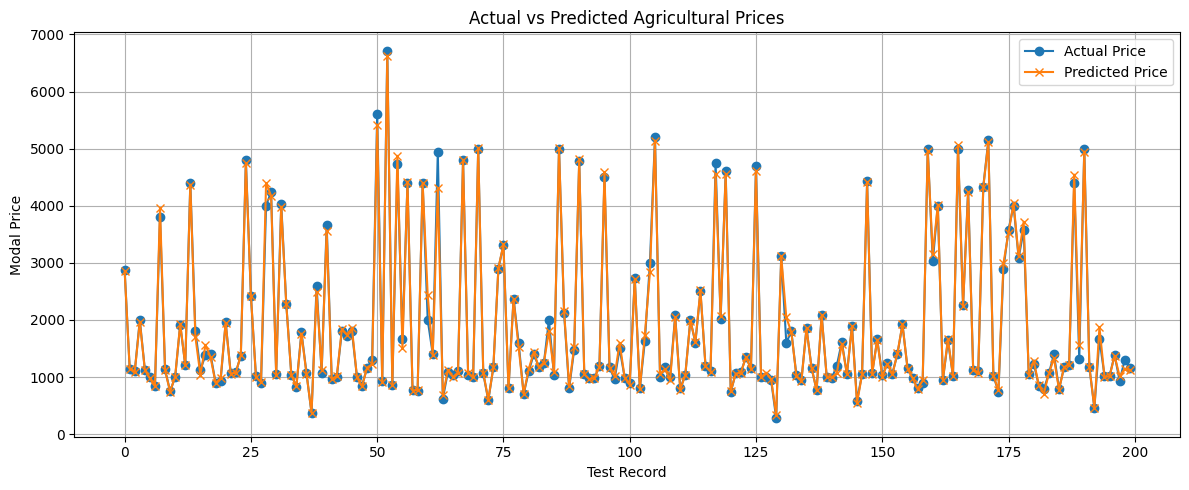

In [55]:
plot_count = min(200, len(y_test))

plt.figure(figsize=(12, 5))

plt.plot(
    y_test.iloc[:plot_count].to_numpy(),
    label="Actual Price",
    marker="o"
)

plt.plot(
    y_pred[:plot_count],
    label="Predicted Price",
    marker="x"
)

plt.title("Actual vs Predicted Agricultural Prices")
plt.xlabel("Test Record")
plt.ylabel("Modal Price")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

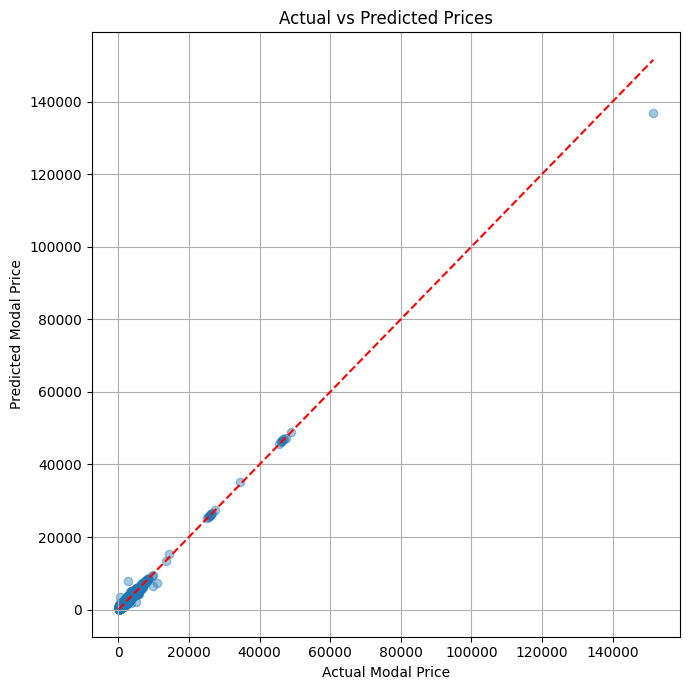

In [57]:
plt.figure(figsize=(7, 7))

plt.scatter(y_test, y_pred, alpha=0.4)

lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())

plt.plot([lower, upper], [lower, upper], "r--")

plt.title("Actual vs Predicted Prices")
plt.xlabel("Actual Modal Price")
plt.ylabel("Predicted Modal Price")
plt.grid(True)
plt.tight_layout()
plt.show()

In [58]:
market_features = (
    weekly.groupby(
        ["STATE", "District Name", "Market Name", "Commodity"],
        observed=True
    )
    .agg(
        Average_Min_Price=("Min_Price", "mean"),
        Average_Max_Price=("Max_Price", "mean"),
        Average_Modal_Price=("Modal_Price", "mean"),
        Price_Std=("Modal_Price", "std")
    )
    .reset_index()
)

market_features["Price_Std"] = market_features["Price_Std"].fillna(0)

cluster_columns = [
    "Average_Min_Price",
    "Average_Max_Price",
    "Average_Modal_Price",
    "Price_Std"
]

print(market_features.head())
print("Markets available for clustering:", len(market_features))

     STATE District Name Market Name Commodity  Average_Min_Price  \
0   Punjab       fazilka      Abohar     Onion        2033.824074   
1   Punjab       fazilka      Abohar    Potato         988.950000   
2   Punjab       fazilka      Abohar    Tomato        3774.129630   
3   Punjab       fazilka     Fazilka     Onion        2138.636364   
4   Punjab       fazilka     Fazilka    Potato        1097.323232   

   Average_Max_Price  Average_Modal_Price    Price_Std  
0        2843.591667          2514.743056  1136.745877  
1        1605.738148          1366.622222   495.728376  
2        5186.388889          4396.833333  2447.420641  
3        3119.204545          2613.257576  1078.855050  
4        1695.033670          1394.865320   637.605741  
Markets available for clustering: 3177


In [59]:
cluster_scaler = StandardScaler()

cluster_data = cluster_scaler.fit_transform(
    market_features[cluster_columns]
)

number_of_clusters = 3

kmeans = KMeans(
    n_clusters=number_of_clusters,
    random_state=42,
    n_init=10
)

market_features["Cluster"] = kmeans.fit_predict(cluster_data)

print("K-Means clustering completed.")
print(market_features["Cluster"].value_counts().sort_index())

K-Means clustering completed.
Cluster
0    2482
1     692
2       3
Name: count, dtype: int64


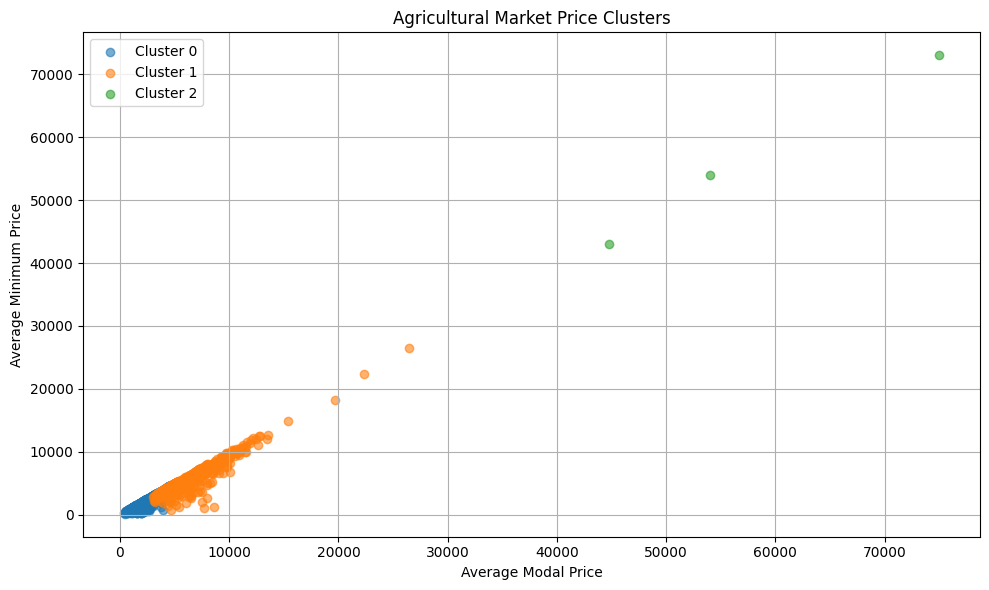

In [60]:
plt.figure(figsize=(10, 6))

for cluster_id in sorted(market_features["Cluster"].unique()):
    cluster_subset = market_features[
        market_features["Cluster"] == cluster_id
    ]

    plt.scatter(
        cluster_subset["Average_Modal_Price"],
        cluster_subset["Average_Min_Price"],
        label=f"Cluster {cluster_id}",
        alpha=0.6
    )

plt.title("Agricultural Market Price Clusters")
plt.xlabel("Average Modal Price")
plt.ylabel("Average Minimum Price")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
cluster_summary = (
    market_features.groupby("Cluster")
    .agg(
        Number_of_Markets=("Market Name", "count"),
        Average_Min_Price=("Average_Min_Price", "mean"),
        Average_Max_Price=("Average_Max_Price", "mean"),
        Average_Modal_Price=("Average_Modal_Price", "mean")
    )
    .round(2)
)

print(cluster_summary)

In [61]:
def forecast_prices(
    commodity,
    weeks=4,
    state=None,
    district=None,
    market=None,
    variety=None,
    grade=None
):
    data = weekly[weekly["Commodity"].astype(str).str.lower()
                  == str(commodity).lower()].copy()

    filters = {
        "STATE": state,
        "District Name": district,
        "Market Name": market,
        "Variety": variety,
        "Grade": grade
    }

    for column, value in filters.items():
        if value is not None:
            data = data[
                data[column].astype(str).str.lower()
                == str(value).lower()
            ]

    if data.empty:
        print("No matching records found.")
        return pd.DataFrame()

    data = data.sort_values("Price Date")
    latest = data.iloc[-1].copy()

    history = data["Modal_Price"].tail(8).tolist()
    results = []

    for step in range(1, weeks + 1):
        next_date = latest["Price Date"] + pd.Timedelta(weeks=1)

        row = {
            "STATE": latest["STATE"],
            "District Name": latest["District Name"],
            "Market Name": latest["Market Name"],
            "Commodity": latest["Commodity"],
            "Variety": latest["Variety"],
            "Grade": latest["Grade"],
            "Min_Price": latest["Min_Price"],
            "Max_Price": latest["Max_Price"],
            "Year": next_date.year,
            "Month": next_date.month,
            "Week": int(next_date.isocalendar().week),
            "DayOfYear": next_date.dayofyear,
            "Lag_1": history[-1],
            "Lag_2": history[-2] if len(history) >= 2 else history[-1],
            "Lag_4": history[-4] if len(history) >= 4 else history[0],
            "Rolling_Mean_4": np.mean(history[-4:]),
            "Rolling_Mean_8": np.mean(history[-8:])
        }

        input_df = pd.DataFrame([row])[feature_columns]
        predicted_price = max(0, float(linear_model.predict(input_df)[0]))

        results.append({
            "STATE": row["STATE"],
            "District Name": row["District Name"],
            "Market Name": row["Market Name"],
            "Commodity": row["Commodity"],
            "Forecast_Date": next_date,
            "Predicted_Modal_Price": round(predicted_price, 2)
        })

        history.append(predicted_price)
        latest["Price Date"] = next_date

    return pd.DataFrame(results)

In [65]:
onion_forecast = forecast_prices(
    commodity="Onion",
    weeks=4
)

print(onion_forecast)

         STATE District Name Market Name Commodity Forecast_Date  \
0  Maharashtra    ahmednagar    Shevgaon     Onion    2025-06-22   
1  Maharashtra    ahmednagar    Shevgaon     Onion    2025-06-29   
2  Maharashtra    ahmednagar    Shevgaon     Onion    2025-07-06   
3  Maharashtra    ahmednagar    Shevgaon     Onion    2025-07-13   

   Predicted_Modal_Price  
0                 617.65  
1                 612.10  
2                 620.09  
3                 623.42  


In [62]:
selected_forecast = forecast_prices(
    commodity="Tomato",
    weeks=4,
    state="Tamil Nadu",
    district="Coimbatore",
    market=None
)

print(selected_forecast)

No matching records found.
Empty DataFrame
Columns: []
Index: []


In [63]:
all_commodity_forecasts = []

for commodity in weekly["Commodity"].dropna().unique():
    result = forecast_prices(
        commodity=commodity,
        weeks=4
    )

    if not result.empty:
        all_commodity_forecasts.append(result)

if all_commodity_forecasts:
    all_forecasts = pd.concat(
        all_commodity_forecasts,
        ignore_index=True
    )
else:
    all_forecasts = pd.DataFrame()

print(all_forecasts.head())
print("Total forecast rows:", len(all_forecasts))

         STATE District Name Market Name Commodity Forecast_Date  \
0  Maharashtra    ahmednagar    Shevgaon     Onion    2025-06-22   
1  Maharashtra    ahmednagar    Shevgaon     Onion    2025-06-29   
2  Maharashtra    ahmednagar    Shevgaon     Onion    2025-07-06   
3  Maharashtra    ahmednagar    Shevgaon     Onion    2025-07-13   
4      Gujarat         kheda   Kapadvanj    Potato    2025-06-22   

   Predicted_Modal_Price  
0                 617.65  
1                 612.10  
2                 620.09  
3                 623.42  
4                1225.21  
Total forecast rows: 20


In [66]:
weekly.to_csv("cleaned_weekly_agriculture_prices.csv", index=False)

market_features.to_csv(
    "agricultural_market_clusters.csv",
    index=False
)

if not all_forecasts.empty:
    all_forecasts.to_csv(
        "all_commodity_price_forecasts.csv",
        index=False
    )

if not onion_forecast.empty:
    onion_forecast.to_csv(
        "onion_price_forecast.csv",
        index=False
    )

print("Files saved successfully.")

Files saved successfully.


In [67]:
import os

print("Current folder:", os.getcwd())
print(os.listdir())

Current folder: C:\Users\HP\ia3
['.ipynb_checkpoints', 'agricultural_market_clusters.csv', 'Agriculture_price_dataset.csv', 'all_commodity_price_forecasts.csv', 'cleaned_weekly_agriculture_prices.csv', 'ia33.ipynb', 'model_test_predictions.csv', 'onion_price_forecast.csv', 'onion_price_forecasts.csv']
